# RANDOM FOREST ALGORITHM
    IN CLASSROOM WE HAVE MORE WEEK LEARNERS AND THEN SAME THINGS HAPPEN IN RANDOM FOREST ALGORITHM WHICH IS IT HAS WEEK LEARNERS INBUILT AND THEN WHAT USING THAT IT WORKS (ITS ENSEMBLE MODEL)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [40]:
# load the dataset

data = pd.read_csv("indian_smartphone_purchases_1m.csv")
print(data)

         customer_id      first_name last_name  age  gender       city  \
0       CUST_0987232  Vishiya_987232      Iyer   19    Male   Hubballi   
1       CUST_0079955     Araan_79955     Patel   57  Female  Ahmedabad   
2       CUST_0567131   Ishaan_567131    Sharma   27  Female    Udaipur   
3       CUST_0500892         Tanitya     Gupta   19    Male   Jabalpur   
4       CUST_0055400     Kavvi_55400     Desai   49    Male     Rajkot   
...              ...             ...       ...  ...     ...        ...   
999995  CUST_0259179     Aadi_259179     Patel   58  Female     Rajkot   
999996  CUST_0365839  Karanan_365839     Gupta   48    Male     Kanpur   
999997  CUST_0131933  Kiransh_131933     Naidu   46  Female  Nizamabad   
999998  CUST_0671156  Yashhna_671156    Pandey   40    Male       Agra   
999999  CUST_0121959    Saaan_121959     Patel   62  Female      Surat   

                 state  pincode    brand           model  ...  storage_gb  \
0            Karnataka   680821   

In [41]:
# check the dataset 
data.shape

(1000000, 21)

In [42]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 21 columns):
 #   Column                    Non-Null Count    Dtype  
---  ------                    --------------    -----  
 0   customer_id               1000000 non-null  object 
 1   first_name                1000000 non-null  object 
 2   last_name                 1000000 non-null  object 
 3   age                       1000000 non-null  int64  
 4   gender                    1000000 non-null  object 
 5   city                      1000000 non-null  object 
 6   state                     1000000 non-null  object 
 7   pincode                   1000000 non-null  int64  
 8   brand                     1000000 non-null  object 
 9   model                     1000000 non-null  object 
 10  ram_gb                    1000000 non-null  int64  
 11  storage_gb                1000000 non-null  int64  
 12  price_inr                 1000000 non-null  float64
 13  discount_applied_percent  10

In [43]:
# check the missing values
data.isnull().sum()

customer_id                 0
first_name                  0
last_name                   0
age                         0
gender                      0
city                        0
state                       0
pincode                     0
brand                       0
model                       0
ram_gb                      0
storage_gb                  0
price_inr                   0
discount_applied_percent    0
purchase_platform           0
payment_method              0
is_exchange_offer           0
delivery_type               0
customer_rating             0
feedback_sentiment          0
purchase_date               0
dtype: int64

In [44]:
#  which platform has more purchase of mobile phone

print(data["purchase_platform"].value_counts())

purchase_platform
Amazon                    420156
Flipkart                  379881
Brand Official Website     79685
Croma                      50258
Reliance Digital           39939
Local Retailer             30081
Name: count, dtype: int64


In [45]:
# remove the customer id 
X = X.drop("customer_id", axis=1)


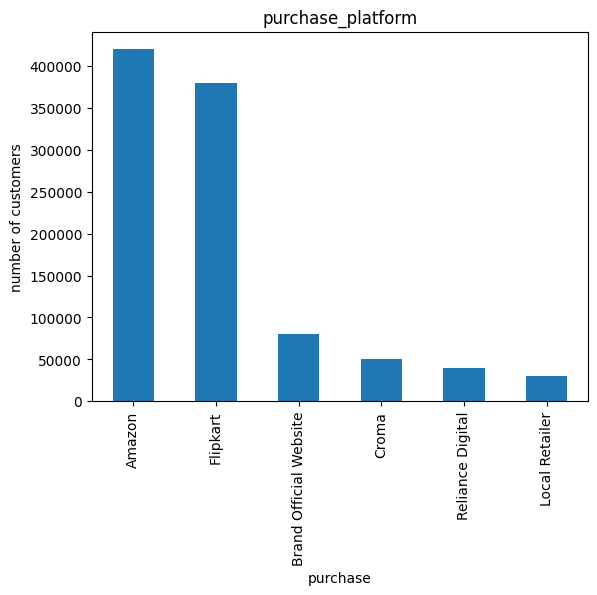

In [46]:
# we need this in visualization 
data["purchase_platform"].value_counts().plot(kind='bar')
plt.title("purchase_platform")
plt.xlabel("purchase")
plt.ylabel("number of customers")
plt.show()

In [36]:
# select featuring 

X = data.drop("purchase_platform", axis=1)
y = data["purchase_platform"]

print("features")
print(X.head())
print("target")
print(y.head())

features
    customer_id      first_name last_name  age  gender       city  \
0  CUST_0987232  Vishiya_987232      Iyer   19    Male   Hubballi   
1  CUST_0079955     Araan_79955     Patel   57  Female  Ahmedabad   
2  CUST_0567131   Ishaan_567131    Sharma   27  Female    Udaipur   
3  CUST_0500892         Tanitya     Gupta   19    Male   Jabalpur   
4  CUST_0055400     Kavvi_55400     Desai   49    Male     Rajkot   

            state  pincode    brand           model  ram_gb  storage_gb  \
0       Karnataka   680821     Vivo        Vivo V30       6         256   
1         Gujarat   273306     OPPO        OPPO A79       6         128   
2       Rajasthan   543226  Samsung      Galaxy S24      12         128   
3  Madhya Pradesh   432742     iQOO  iQOO Neo 9 Pro       6         256   
4         Gujarat   418008  Samsung      Galaxy F14       8         256   

   price_inr  discount_applied_percent    payment_method  is_exchange_offer  \
0   25016.60                        25  Cash o

In [37]:
# split for train and test 
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42, stratify=y)
print("training sample",len(X_train))
print("testing sample",len(X_test))

training sample 800000
testing sample 200000


# built the random forest model
# what is random forest ?
     random forest it create multiple decision tree 
     n_estimators=100 it will contain 100 decision trees
     for this beginner exampe : we do not need features scaling because random forest is tree-based model
 

In [38]:
# built the random forest model

model = RandomForestClassifier(n_estimators=100,random_state=42)
model.fit(X_train, y_train)
print("random forest trained successfully")


ValueError: could not convert string to float: 'CUST_0554269'

# what happens where we got the model training error 
     so what we are going is they will see the datatype and convert all the datatype in same datatype

In [27]:
print(X_train.dtypes)

customer_id                  object
first_name                   object
last_name                    object
age                           int64
gender                       object
city                         object
state                        object
pincode                       int64
brand                        object
model                        object
ram_gb                        int64
storage_gb                    int64
price_inr                   float64
discount_applied_percent      int64
payment_method               object
is_exchange_offer              bool
delivery_type                object
customer_rating               int64
feedback_sentiment           object
purchase_date                object
dtype: object


In [28]:
# check what are the object in columns
print(X_train.select_dtypes(include="object").columns)

Index(['customer_id', 'first_name', 'last_name', 'gender', 'city', 'state',
       'brand', 'model', 'payment_method', 'delivery_type',
       'feedback_sentiment', 'purchase_date'],
      dtype='object')


In [29]:
# first remove the unnecessary columns 
X = X.drop(
    ["customer_id", "first_name", "last_name"],
    axis=1
)

In [30]:
# Label Encoding - for suitable columns

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

X["gender"] = le.fit_transform(X["gender"])
X["feedback_sentiment"] = le.fit_transform(X["feedback_sentiment"])

In [31]:
# One-Hot Encoding - for suitable columns
X = pd.get_dummies(
    X,
    columns=[
        "city",
        "state",
        "brand",
        "model",
        "payment_method",
        "delivery_type"
    ],
    dtype=int
)


In [32]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 21 columns):
 #   Column                    Non-Null Count    Dtype  
---  ------                    --------------    -----  
 0   customer_id               1000000 non-null  object 
 1   first_name                1000000 non-null  object 
 2   last_name                 1000000 non-null  object 
 3   age                       1000000 non-null  int64  
 4   gender                    1000000 non-null  object 
 5   city                      1000000 non-null  object 
 6   state                     1000000 non-null  object 
 7   pincode                   1000000 non-null  int64  
 8   brand                     1000000 non-null  object 
 9   model                     1000000 non-null  object 
 10  ram_gb                    1000000 non-null  int64  
 11  storage_gb                1000000 non-null  int64  
 12  price_inr                 1000000 non-null  float64
 13  discount_applied_percent  10

In [33]:
# check the changes happen in that dataset
print(X.head())


   age  gender  pincode  ram_gb  storage_gb  price_inr  \
0   19       1   680821       6         256   25016.60   
1   57       0   273306       6         128   12111.57   
2   27       0   543226      12         128   49072.37   
3   19       1   432742       6         256   14496.07   
4   49       1   418008       8         256   69362.50   

   discount_applied_percent  is_exchange_offer  customer_rating  \
0                        25               True                2   
1                        15              False                4   
2                         0               True                4   
3                        10              False                4   
4                         0              False                5   

   feedback_sentiment  ... model_iQOO Z7s  model_iQOO Z9  \
0                   2  ...              0              0   
1                   1  ...              0              0   
2                   2  ...              0              0   
3       

# after the dataset is changed we can do the train test split again

In [39]:
# select featuring  -2

X = data.drop("purchase_platform", axis=1)
y = data["purchase_platform"]

print("features")
print(X.head())
print("target")
print(y.head())

features
    customer_id      first_name last_name  age  gender       city  \
0  CUST_0987232  Vishiya_987232      Iyer   19    Male   Hubballi   
1  CUST_0079955     Araan_79955     Patel   57  Female  Ahmedabad   
2  CUST_0567131   Ishaan_567131    Sharma   27  Female    Udaipur   
3  CUST_0500892         Tanitya     Gupta   19    Male   Jabalpur   
4  CUST_0055400     Kavvi_55400     Desai   49    Male     Rajkot   

            state  pincode    brand           model  ram_gb  storage_gb  \
0       Karnataka   680821     Vivo        Vivo V30       6         256   
1         Gujarat   273306     OPPO        OPPO A79       6         128   
2       Rajasthan   543226  Samsung      Galaxy S24      12         128   
3  Madhya Pradesh   432742     iQOO  iQOO Neo 9 Pro       6         256   
4         Gujarat   418008  Samsung      Galaxy F14       8         256   

   price_inr  discount_applied_percent    payment_method  is_exchange_offer  \
0   25016.60                        25  Cash o

In [47]:
# selecting the feature columns

X = data[["model"]]
y = data["purchase_platform"]

In [50]:
# convert the model col into numberics
X = pd.get_dummies(X, columns=["model"], dtype=int)

In [51]:
# split for train and test 
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42, stratify=y)
print("training sample",len(X_train))
print("testing sample",len(X_test))

training sample 800000
testing sample 200000


In [52]:
# built the random forest model

model = RandomForestClassifier(n_estimators=100,random_state=42)
model.fit(X_train, y_train)
print("random forest trained successfully")

random forest trained successfully


In [54]:
# model predict 
y_predict = model.predict(X_test)

print("actual values:")
print(y_test.values)
print("predicted values")
print(y_predict)

actual values:
['Amazon' 'Amazon' 'Flipkart' ... 'Amazon' 'Flipkart' 'Flipkart']
predicted values
['Amazon' 'Amazon' 'Amazon' ... 'Amazon' 'Amazon' 'Amazon']


In [56]:
#evaluate the model
accuracy = accuracy_score(y_test, y_predict)
print(accuracy)
print(classification_report(y_test,y_predict,zero_division=0))


0.420155
                        precision    recall  f1-score   support

                Amazon       0.42      1.00      0.59     84031
Brand Official Website       0.00      0.00      0.00     15937
                 Croma       0.00      0.00      0.00     10052
              Flipkart       0.00      0.00      0.00     75976
        Local Retailer       0.00      0.00      0.00      6016
      Reliance Digital       0.00      0.00      0.00      7988

              accuracy                           0.42    200000
             macro avg       0.07      0.17      0.10    200000
          weighted avg       0.18      0.42      0.25    200000



In [58]:
# confusion matrix
cm  = confusion_matrix(y_test, y_predict)

print("confusion matrix")
print(cm)



confusion matrix
[[84031     0     0     0     0     0]
 [15937     0     0     0     0     0]
 [10052     0     0     0     0     0]
 [75976     0     0     0     0     0]
 [ 6016     0     0     0     0     0]
 [ 7988     0     0     0     0     0]]
